# Chapter 11 — Matplotlib: Foundational Data Visualization

Matplotlib is the core plotting library. Learn figures, axes, plot types, labels, scales, legends, layout, and export controls.

## Prerequisites
NumPy/Pandas basics; install Matplotlib.

## Learning goals
- Distinguish Figure and Axes objects.
- Create line, bar, scatter, histogram, and box plots.
- Control labels, scales, legends, grids, and layouts.
- Export charts with readable dimensions and resolution.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Chapter map

1. Figure and Axes
2. Figure construction
3. Chart methods
4. Axes and annotations
5. Export and accessibility

### Figure and Axes
A Figure is the overall canvas; an Axes is one plotting area. Prefer `fig, ax = plt.subplots(...)`, then `ax.plot`, `ax.set_title`, and `ax.legend`. Stateful `plt` functions are quick shortcuts; the object-oriented API is easier for multi-panel charts and reusable functions.

#### Demonstration 1 — Create a basic line chart

Run the code and inspect both the output and the assumptions behind it.

/mnt/data/python_data_analysis_book/Chapter_11_matplotlib_foundational_data_visualization/Chapter_11_Concepts_and_Theory.ipynb:4: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



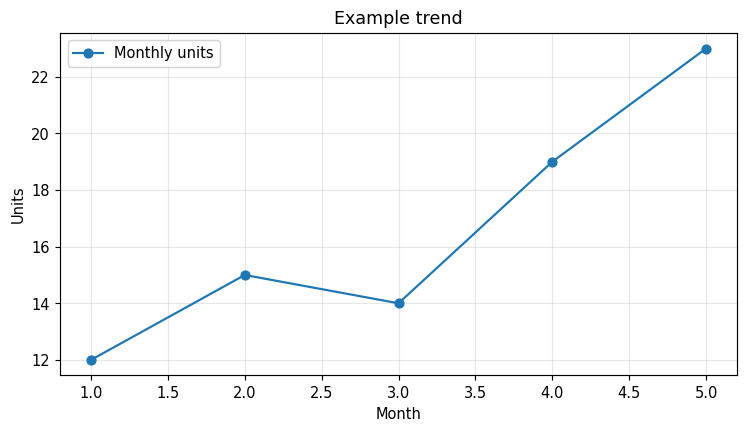

In [2]:
import numpy as np, matplotlib.pyplot as plt
x=np.arange(1,6); y=np.array([12,15,14,19,23])
fig,ax=plt.subplots(figsize=(7,4),layout="constrained")
ax.plot(x,y,marker="o",label="Monthly units"); ax.set(title="Example trend",xlabel="Month",ylabel="Units"); ax.grid(True,alpha=.3); ax.legend(); plt.show()

### Figure construction
`plt.subplots(nrows=1,ncols=1,figsize=None,sharex=False,sharey=False,squeeze=True,layout=None)` returns a Figure and Axes. `figsize` uses inches; `sharex/sharey` synchronize axes; `squeeze=False` guarantees a 2-D axes array; `layout="constrained"` helps prevent clipping. Save via `fig.savefig(fname,dpi=...,bbox_inches="tight")`; close figures in loops.

#### Demonstration 2 — Aggregate revenue by region

Run the code and inspect both the output and the assumptions behind it.

Data directory: /mnt/data/python_data_analysis_book/data


/mnt/data/python_data_analysis_book/Chapter_11_matplotlib_foundational_data_visualization/Chapter_11_Concepts_and_Theory.ipynb:8: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



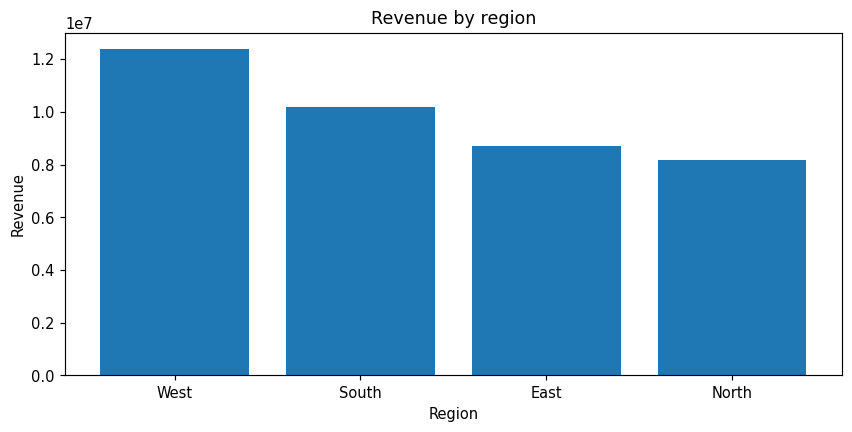

In [3]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())
import pandas as pd, matplotlib.pyplot as plt
sales=pd.read_csv(DATA/"sales.csv"); region=sales.groupby("region").revenue.sum().sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(8,4),layout="constrained"); ax.bar(region.index,region.values); ax.set(title="Revenue by region",xlabel="Region",ylabel="Revenue"); plt.show()

### Chart methods
`ax.plot(x,y,marker,linestyle,linewidth,label)` shows trends; `bar`/`barh` compares categories; `scatter(x,y,s,c,alpha)` shows relationships; `hist(x,bins,density,cumulative)` shows distributions; `boxplot` shows quartiles and potential outliers. Select chart type based on variable types and the analytical question.

#### Demonstration 3 — Plot daily revenue

Run the code and inspect both the output and the assumptions behind it.

/mnt/data/python_data_analysis_book/Chapter_11_matplotlib_foundational_data_visualization/Chapter_11_Concepts_and_Theory.ipynb:3: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



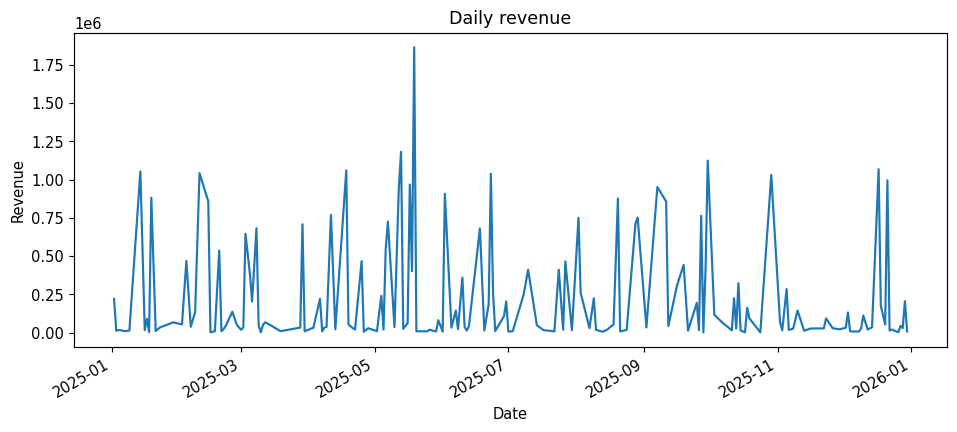

In [4]:
sales["order_date"]=pd.to_datetime(sales.order_date)
daily=sales.groupby("order_date").revenue.sum().sort_index()
fig,ax=plt.subplots(figsize=(9,4),layout="constrained"); ax.plot(daily.index,daily.values); ax.set(title="Daily revenue",xlabel="Date",ylabel="Revenue"); fig.autofmt_xdate(); plt.show()

### Axes and annotations
Use `set_title`, `set_xlabel`, `set_ylabel`, `set_xlim`, `set_ylim`, `set_xscale`, `set_yscale`, `grid`, and `legend`. Log scales change visual interpretation; label them. Avoid misleading truncated axes and make units, periods, and denominator clear.

#### Demonstration 4 — Plot a distribution and multiple panels

Run the code and inspect both the output and the assumptions behind it.

/mnt/data/python_data_analysis_book/Chapter_11_matplotlib_foundational_data_visualization/Chapter_11_Concepts_and_Theory.ipynb:3: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



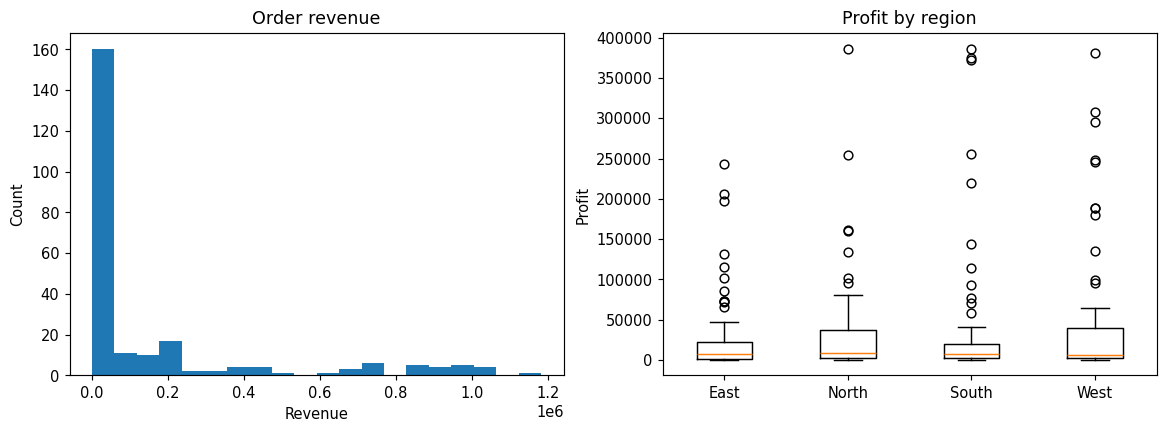

In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained")
axes[0].hist(sales.revenue,bins=20); axes[0].set(title="Order revenue",xlabel="Revenue",ylabel="Count")
axes[1].boxplot([sales.loc[sales.region==r,"profit"] for r in sorted(sales.region.unique())],tick_labels=sorted(sales.region.unique())); axes[1].set(title="Profit by region",ylabel="Profit"); plt.show()

### Export and accessibility
`dpi` controls raster resolution; SVG/PDF are vector formats. Keep labels readable at the final size, check contrast, and do not encode critical meaning by color alone. Save the final figure after setting labels and layout.

#### Demonstration 5 — Save raster and vector outputs

Run the code and inspect both the output and the assumptions behind it.

In [6]:
fig.savefig("sales_plot.png",dpi=150,bbox_inches="tight"); fig.savefig("sales_plot.svg",bbox_inches="tight"); print("Saved PNG and SVG")

Saved PNG and SVG


## Self-check

Without looking back, explain the key terms, identify the important parameters, describe at least one alternative or variation, and state one limitation of the methods covered. Then answer the exercises below.

### Review questions

- Explain one important concept from: Figure and Axes.
- Explain one important concept from: Figure construction.
- Explain one important concept from: Chart methods.
- Explain one important concept from: Axes and annotations.
- Explain one important concept from: Export and accessibility.